# Leave-One-Individual-Out Cross-Validation - Vnet Green Turtles (pytorch)

Condensed version of `B=Training the Vnet_Green Turtles_pytorch.ipynb` that wraps the whole
training/testing pipeline in a **leave-one-out cross-validation (LOOCV) loop over individuals**.

Recording names are `<camera>_<date>[_<part>]`. The `CC-0X-XX` part is the **camera ID**, not the
turtle — the same camera is reused across different animals. So, by default, each distinct
`camera + date` combination is treated as a separate individual, and a same-day recording split
into several files (e.g. `CC-07-48_08-04-2019_1/_2/_3`) is merged back into one individual/session.
The one confirmed exception is `CC-07-115_13-05-2019` and `CC-07-115_14-05-2019`, which are two
consecutive days of the **same** individual and are merged into a single individual (see
`INDIVIDUAL_OVERRIDES`).

For each fold, every recording of one individual is held out as the test set, and all recordings of
the other individuals are used for training/validation. The macro F1-score is computed on the
held-out individual at the end of every fold, then averaged over all folds at the end of the
notebook.

## Setup

In [1]:
import sys
import os
sys.path.append(os.path.abspath('c:/Users/loren/Documents/Tortues/Martinique_Verte'))
os.chdir(r"C:\Users\loren\Documents\Tortues\Martinique_Verte")
print(os.getcwd())

C:\Users\loren\Documents\Tortues\Martinique_Verte


In [2]:
import json
import re
import time
import datetime
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from tqdm import tqdm
from sklearn.metrics import confusion_matrix

np.set_printoptions(precision=2, suppress=True, linewidth=50000)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## Parameters

In [4]:
CASE = "TestA_pressurecorrected_LOOCV"

class classCLASS:
    def __init__(self, id, name, behaviors, score_weight, sampling_weight=1, loss_weight=1):
        self.id = id
        self.name = name
        self.behaviors = behaviors
        self.score_weight = score_weight
        self.sampling_weight = sampling_weight
        self.loss_weight = loss_weight

Other      = classCLASS(0, "Other", None, 0, 1, 0.1)
Breathing  = classCLASS(1, "Breathing", [1,2,40], 1)
Feeding    = classCLASS(2, "Feeding", [3,4,5,6,7,11,12,13,18,19,20,21], 10, 2, 2)
Gliding    = classCLASS(3, "Gliding", [16,17], 1, 3)
Resting    = classCLASS(4, "Resting", [29,30,31,32], 1, 0.5)
Scratching = classCLASS(5, "Scratching", [34,35,36], 2, 2, 2)
Swimming   = classCLASS(6, "Swimming", [42,45,48,43,46,49,27,44,47,50,56,52,54,55], 1, 0.5)

CLASSES = [Other, Breathing, Feeding, Gliding, Resting, Scratching, Swimming]
CLASS_NAMES = [CLASS.name for CLASS in CLASSES]

DESCRIPTORS_SELEC = [1,2,3,4,5,6,24]   # variables used to train the Vnet
WINDOW_DURA = 40                        # window size in seconds
RESAMPLING_STEP_S = 0.0500              # freq of the csv files
DIR_IN = "out_A_09062025"               # where to find the data
WINDOW_SIZE = int(WINDOW_DURA / RESAMPLING_STEP_S)
COL_BEH = 27

# Vnet hyperparameters
LR_initial = 0.0001
BATCH_SIZE = 32
MODEL_DEPTH = 32
DROPOUT = 0.5

# Loss: combined Dice + weighted cross-entropy (see the loss cell for why pure
# Dice alone tends to collapse on imbalanced multi-class targets)
DICE_LOSS_WEIGHT = 0.5
CE_LOSS_WEIGHT = 0.5

# LOOCV / training-loop settings
EPOCHS_PER_FOLD = 50         # upper bound on epochs; a fold usually stops earlier (see PATIENCE)
PATIENCE = 15                 # stop a fold's training after this many epochs with no val_loss improvement
NB_TRAIN_PER_EPOCH = 10000
NB_VAL_PER_EPOCH = 6000
N_VAL_INDIVIDUALS_PER_FOLD = 2  # how many of the *remaining* individuals are held out for validation

## Recordings, grouped by individual

In [5]:
# All available recordings (same pool as the original training notebook's
# NAMES_TRAIN + NAMES_VAL + NAMES_TEST).
NAMES_ALL = [
    'CC-07-48_18-02-2019',
    'CC-07-48_06-10-2018',
    'CC-07-48_04-10-2018',
    'CC-07-115_13-05-2019',
    'CC-07-115_14-05-2019',
    'CC-07-48_08-04-2019_1',
    'CC-07-48_08-04-2019_2',
    'CC-07-48_08-04-2019_3',
    'CC-07-48_22-05-2018',
    'CC-07-108_11-02-2019',
    'CC-07-59_20-05-2018',
    'CC-07-47_14-02-2018',
    'CC-07-48_10-10-2018',
    'CC-07-48_08-10-2018',
    'CC-07-48_26-05-2018',
    'CC-07-107_11-02-2019',
]

# Recordings confirmed to be multiple sessions of the SAME individual despite having
# different dates (unlike the camera+date default below). Add entries here as more
# multi-day deployments are identified.
INDIVIDUAL_OVERRIDES = {
    'CC-07-115_13-05-2019': 'CC-07-115_13-05-2019+14-05-2019',
    'CC-07-115_14-05-2019': 'CC-07-115_13-05-2019+14-05-2019',
}

def individual_id_of(name):
    """'CC-07-48_08-04-2019_1' -> 'CC-07-48_08-04-2019' (same camera+date, just a
    split file -> same individual/session), unless overridden in INDIVIDUAL_OVERRIDES."""
    if name in INDIVIDUAL_OVERRIDES:
        return INDIVIDUAL_OVERRIDES[name]
    return re.sub(r'_\d+$', '', name)   # strip a trailing '_<part number>' suffix

INDIVIDUAL_TO_NAMES = defaultdict(list)
for name in NAMES_ALL:
    INDIVIDUAL_TO_NAMES[individual_id_of(name)].append(name)

INDIVIDUAL_IDS = sorted(INDIVIDUAL_TO_NAMES.keys())

print(f"{len(NAMES_ALL)} recordings, {len(INDIVIDUAL_IDS)} distinct individuals:")
for iid in INDIVIDUAL_IDS:
    print(f"  {iid}: {len(INDIVIDUAL_TO_NAMES[iid])} recording(s) -> {INDIVIDUAL_TO_NAMES[iid]}")

16 recordings, 13 distinct individuals:
  CC-07-107_11-02-2019: 1 recording(s) -> ['CC-07-107_11-02-2019']
  CC-07-108_11-02-2019: 1 recording(s) -> ['CC-07-108_11-02-2019']
  CC-07-115_13-05-2019+14-05-2019: 2 recording(s) -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019']
  CC-07-47_14-02-2018: 1 recording(s) -> ['CC-07-47_14-02-2018']
  CC-07-48_04-10-2018: 1 recording(s) -> ['CC-07-48_04-10-2018']
  CC-07-48_06-10-2018: 1 recording(s) -> ['CC-07-48_06-10-2018']
  CC-07-48_08-04-2019: 3 recording(s) -> ['CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3']
  CC-07-48_08-10-2018: 1 recording(s) -> ['CC-07-48_08-10-2018']
  CC-07-48_10-10-2018: 1 recording(s) -> ['CC-07-48_10-10-2018']
  CC-07-48_18-02-2019: 1 recording(s) -> ['CC-07-48_18-02-2019']
  CC-07-48_22-05-2018: 1 recording(s) -> ['CC-07-48_22-05-2018']
  CC-07-48_26-05-2018: 1 recording(s) -> ['CC-07-48_26-05-2018']
  CC-07-59_20-05-2018: 1 recording(s) -> ['CC-07-59_20-05-2018']


In [6]:
now = datetime.datetime.now()
today = now.strftime("%Y_%m_%d")

DIR_OUT_BASE = "Model_results/model=" + today + "_" + CASE
os.makedirs(DIR_OUT_BASE, exist_ok=True)
DIR_OUT_BASE

'Model_results/model=2026_09_25_TestA_pressurecorrected_LOOCV'

## Load the data (once, shared across all folds)

In [7]:
def load_dico(path, key_int=False, print_me=False):
    with open(path) as f:
        dico_str = json.loads(json.load(f))
    conv_key = (lambda k: int(k)) if key_int else (lambda k: k)
    dico = {conv_key(k): v for k, v in dico_str.items()}
    if print_me:
        print(dico)
    return dico

dico_info_A = load_dico(DIR_IN + "/dico_info.json", print_me=True)
DESC_NAMES = dico_info_A['col_names']
DESC_NAMES_SELEC = [DESC_NAMES[i] for i in DESCRIPTORS_SELEC]
print("Descriptors used:", DESC_NAMES_SELEC)

{'RESAMPLING_STEP_S': 0.05, 'col_names': ['index', 'Accelerometer X [m/s²]', 'Accelerometer Y [m/s²]', 'Accelerometer Z [m/s²]', 'Gyroscope X [mrad/s]', 'Gyroscope Y [mrad/s]', 'Gyroscope Z [mrad/s]', 'Magnetometer X [µT]', 'Magnetometer Y [µT]', 'Magnetometer Z [µT]', 'Depth [m]', 'Light intensity 1 [raw]', 'Temperature (imu) [°C]', 'StX', 'StY', 'StZ', 'DX', 'DY', 'DZ', 'dba', 'AccX_high', 'AccY_high', 'AccZ_high', 'Pressure_corr', 'Pressure_diff_1s', 'Pressure_diff_2s', 'Pressure_diff_3s', 'beh']}
Descriptors used: ['Accelerometer X [m/s²]', 'Accelerometer Y [m/s²]', 'Accelerometer Z [m/s²]', 'Gyroscope X [mrad/s]', 'Gyroscope Y [mrad/s]', 'Gyroscope Z [mrad/s]', 'Pressure_diff_1s']


In [8]:
def load_mat(names):
    matrices, labels = {}, {}
    for name in names:
        full_name = DIR_IN + "/" + name + ".npy"
        assert os.path.exists(full_name), "the file:" + full_name + " cannot be found"
        full_mat = np.load(full_name)
        pre_label = full_mat[:, COL_BEH]

        label = np.zeros_like(pre_label)
        for CLASS in CLASSES:
            if CLASS != Other:
                for beh in CLASS.behaviors:
                    label[pre_label == beh] = CLASS.id

        mat = full_mat[:, DESCRIPTORS_SELEC]
        matrices[name] = mat
        labels[name] = label
        print(f"loaded {name}: shape {mat.shape}, duration {len(mat)*RESAMPLING_STEP_S/3600:.2f} h")

    return matrices, labels

matrices, labels = load_mat(NAMES_ALL)

loaded CC-07-48_18-02-2019: shape (559219, 7), duration 7.77 h
loaded CC-07-48_06-10-2018: shape (475183, 7), duration 6.60 h
loaded CC-07-48_04-10-2018: shape (284021, 7), duration 3.94 h
loaded CC-07-115_13-05-2019: shape (731266, 7), duration 10.16 h
loaded CC-07-115_14-05-2019: shape (325009, 7), duration 4.51 h
loaded CC-07-48_08-04-2019_1: shape (157315, 7), duration 2.18 h
loaded CC-07-48_08-04-2019_2: shape (88800, 7), duration 1.23 h
loaded CC-07-48_08-04-2019_3: shape (142801, 7), duration 1.98 h
loaded CC-07-48_22-05-2018: shape (286161, 7), duration 3.97 h
loaded CC-07-108_11-02-2019: shape (160292, 7), duration 2.23 h
loaded CC-07-59_20-05-2018: shape (423855, 7), duration 5.89 h
loaded CC-07-47_14-02-2018: shape (105362, 7), duration 1.46 h
loaded CC-07-48_10-10-2018: shape (69239, 7), duration 0.96 h
loaded CC-07-48_08-10-2018: shape (535201, 7), duration 7.43 h
loaded CC-07-48_26-05-2018: shape (267301, 7), duration 3.71 h
loaded CC-07-107_11-02-2019: shape (346142, 7),

In [9]:
def normalize():
    nb_col = matrices[NAMES_ALL[0]].shape[1]
    for matrix in matrices.values():
        for j in range(nb_col):
            matrix[:, j] -= matrix[:, j].mean()
            matrix[:, j] /= matrix[:, j].std()

normalize()

## Data generator (unchanged from the original notebook)

In [10]:
def density_for_one_promotion(turtle_name, CLASS):
    label = labels[turtle_name]
    dens = np.zeros_like(label)
    dens[label == CLASS.id] = 1

    sum_dens = np.sum(dens)
    if sum_dens < 1e-6:
        dens[:] = 1
        sum_dens = len(dens)
    dens /= sum_dens

    kernel = np.ones(int(1.5 * WINDOW_SIZE))
    kernel /= np.sum(kernel)
    dens_conv = np.convolve(dens, kernel, mode='same')
    dens_conv[-WINDOW_SIZE // 2 - 2:] = 0
    dens_conv[:WINDOW_SIZE // 2 + 2] = 0

    cdf = np.cumsum(dens_conv)
    cdf /= cdf[-1]

    def rand_gene():
        while True:
            yield np.argmax(cdf > np.random.random()) - WINDOW_SIZE // 2

    return rand_gene()


class InterestingTurtles:
    def __init__(self, turtle_names, CLASS):
        self.turtle_names = turtle_names
        self.occurences = np.zeros(len(turtle_names))
        self.CLASS = CLASS
        for i, name in enumerate(turtle_names):
            self.occurences[i] += np.sum(labels[name] == CLASS.id)
        self.proba = self.occurences / np.sum(self.occurences)

    def give_me_one_turtle(self):
        return np.random.choice(a=self.turtle_names, p=self.proba)


class Global_generator:
    def __init__(self, turtle_names):
        self.turtle_names = turtle_names
        self.interesting_turtles_by_class = {}
        self.proba_of_classes = np.zeros(len(CLASSES))

        for CLASS in CLASSES:
            self.interesting_turtles_by_class[CLASS.name] = InterestingTurtles(turtle_names, CLASS)
            self.proba_of_classes[CLASS.id] = CLASS.sampling_weight
        self.proba_of_classes /= np.sum(self.proba_of_classes)

        self.class_2_index_gene = {}
        for CLASS in CLASSES:
            random_index_generators = {}
            for name in turtle_names:
                random_index_generators[name] = density_for_one_promotion(name, CLASS)
            self.class_2_index_gene[CLASS.name] = random_index_generators

    def give_me_turtle_and_timeIndex(self):
        if np.random.rand() < 0.1:
            theTurtle = np.random.choice(self.turtle_names)
            deb = 0
            fin = len(labels[theTurtle]) - WINDOW_SIZE
            t = np.random.randint(deb, fin)
            return theTurtle, t

        theClass = np.random.choice(CLASSES, p=self.proba_of_classes)
        theTurtle = self.interesting_turtles_by_class[theClass.name].give_me_one_turtle()
        theGenerator = self.class_2_index_gene[theClass.name][theTurtle]
        return theTurtle, next(theGenerator)


def oneEpoch_generator_window(turtle_names, size=100):
    generator = Global_generator(turtle_names)
    while True:
        X = np.empty([size, WINDOW_SIZE, len(DESCRIPTORS_SELEC)])
        Y = np.empty([size, WINDOW_SIZE], dtype=int)
        for i in range(size):
            turtle_name, t = generator.give_me_turtle_and_timeIndex()
            matrix = matrices[turtle_name]
            label = labels[turtle_name]
            X[i, :, :] = matrix[t:t + WINDOW_SIZE, :]
            Y[i, :] = label[t:t + WINDOW_SIZE]
        yield X, Y

## Vnet model (unchanged from the original notebook)

In [11]:
class SpatialDropout1D(nn.Module):
    def __init__(self, p: float = 0.5):
        """Drops entire channels (features) across all timesteps of a
        (batch_size, channels, sequence_length) input."""
        super(SpatialDropout1D, self).__init__()
        self.dropout = nn.Dropout2d(p)

    def forward(self, x):
        x = x.unsqueeze(3)      # add a fake height dimension (N, C, L, 1)
        x = self.dropout(x)     # apply Dropout2d
        return x.squeeze(3)


class VNet4Levels(nn.Module):
    def __init__(self, in_channels, out_channels, model_depth, dropout_rate=0.5, kernel_size=5):
        super(VNet4Levels, self).__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.depth = model_depth
        self.dropout_rate = dropout_rate
        self.kernel_size = kernel_size

        self.dropout = SpatialDropout1D(p=dropout_rate)

        self.conv1 = self.double_conv(self.in_channels, self.depth)
        self.down1 = nn.Conv1d(self.depth, self.depth * 2, kernel_size=2, stride=2, padding=0)
        self.conv2 = self.double_conv(self.depth * 2, self.depth * 2)

        self.down2 = nn.Conv1d(self.depth * 2, self.depth * 4, kernel_size=2, stride=2, padding=0)
        self.conv3 = self.double_conv(self.depth * 4, self.depth * 4)

        self.down3 = nn.Conv1d(self.depth * 4, self.depth * 8, kernel_size=2, stride=2, padding=0)
        self.conv4 = self.double_conv(self.depth * 8, self.depth * 8)

        self.up1 = self.make_up(self.depth * 8, self.depth * 4)
        self.conv5 = self.double_conv(self.depth * 4, self.depth * 4)

        self.up2 = self.make_up(self.depth * 4, self.depth * 2)
        self.conv6 = self.double_conv(self.depth * 2, self.depth * 2)

        self.up3 = self.make_up(self.depth * 2, self.depth)
        self.conv7 = self.double_conv(self.depth, self.depth)

        self.classifier = nn.Conv1d(self.depth, self.out_channels, kernel_size=1)

    def double_conv(self, in_channels, depth):
        return nn.Sequential(
            nn.Conv1d(in_channels, depth, self.kernel_size, padding=2),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True),
            nn.Conv1d(depth, depth, self.kernel_size, padding=2, bias=False),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True),
        )

    def make_up(self, in_channels, depth):
        return nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv1d(in_channels, depth, kernel_size=3, padding=1),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        conv1 = self.conv1(x)
        conv1_d = self.dropout(conv1)
        down1 = F.relu(self.down1(conv1_d))
        conv2 = self.conv2(down1)
        conv2_d = self.dropout(conv2)

        y = torch.add(down1, conv2_d)
        down2 = F.relu(self.down2(y))
        conv3 = self.conv3(down2)
        conv3_d = self.dropout(conv3)

        y = torch.add(down2, conv3_d)
        down3 = F.relu(self.down3(y))
        conv4 = self.conv4(down3)
        conv4_d = self.dropout(conv4)

        # PATCH_DIM/4
        up1 = self.up1(conv4_d)
        y = torch.add(conv3_d, up1)
        pre_conv5 = self.conv5(y)
        pre_conv5_d = self.dropout(pre_conv5)
        conv5 = torch.add(pre_conv5_d, up1)

        # PATCH_DIM/2
        up2 = self.up2(conv5)
        y = torch.add(conv2, up2)
        pre_conv6 = self.conv6(y)
        pre_conv6_d = self.dropout(pre_conv6)
        conv6 = torch.add(pre_conv6_d, up2)

        # PATCH_DIM
        up3 = self.up3(conv6)
        y = torch.add(conv1, up3)
        pre_conv7 = self.conv7(y)
        pre_conv7_d = self.dropout(pre_conv7)
        conv7 = torch.add(pre_conv7_d, up3)

        output = self.classifier(conv7)
        return F.softmax(output, dim=1)

In [12]:
def dice_coef(pred_proba, target_onehot, smooth=1e-8):
    intersection = torch.sum(target_onehot * pred_proba, dim=2)
    return (2. * intersection + smooth) / (torch.sum(target_onehot, dim=2) + torch.sum(pred_proba, dim=2) + smooth)

def dice_loss(pred_proba, target_onehot, weight):
    """`weight` is normalized to sum to 1 (see `ponde` below), so summing the
    weighted per-class dice over the class axis already gives the correct
    per-sample weighted-average dice score. Averaging over the class axis
    too (i.e. calling .mean() directly on the (batch, num_classes) tensor,
    as the original notebook did) silently divides the score by an extra,
    unintended factor of num_classes: perfect predictions would then floor
    out at loss ~= 1 - 1/num_classes instead of ~0, crushing almost all of
    the loss's useful dynamic range and starving the model of gradient
    signal."""
    weight = weight.view(1, -1).to(pred_proba.device)
    weighted_dice = dice_coef(pred_proba, target_onehot) * weight
    return 1 - weighted_dice.sum(dim=1).mean()

def weighted_ce_loss(pred_proba, target_onehot, weight, eps=1e-8):
    """Weighted per-timestep cross-entropy on already-softmaxed predictions."""
    weight = weight.view(1, -1, 1).to(pred_proba.device)
    log_probs = torch.log(pred_proba.clamp(min=eps))
    per_timestep = -(target_onehot * log_probs * weight).sum(dim=1)   # (N, L)
    return per_timestep.mean()

def dice_ce_loss(pred_proba, target_onehot, weight):
    """Combined Dice + weighted cross-entropy. A pure Dice loss on imbalanced
    multi-class targets gives weak/unstable gradients for rare classes (its
    gradient vanishes when both the true and predicted masks are near-empty),
    which is a common cause of a segmentation model collapsing onto only the
    dominant class(es). Cross-entropy gives every timestep a steady per-pixel
    gradient regardless of how rare its class is, so mixing it in stabilizes
    training on the rare behaviors."""
    return (DICE_LOSS_WEIGHT * dice_loss(pred_proba, target_onehot, weight)
            + CE_LOSS_WEIGHT * weighted_ce_loss(pred_proba, target_onehot, weight))

ponde = torch.tensor(np.array([CLASS.loss_weight for CLASS in CLASSES], dtype=np.float32))
ponde /= torch.sum(ponde)
ponde

tensor([0.0123, 0.1235, 0.2469, 0.1235, 0.1235, 0.2469, 0.1235])

## Trainer

Same training logic as the original notebook, plus a working early-stopping check (the original
notebook had a `patience`/`counter` mechanism but its `break` was commented out, so it never
actually stopped early — here it does). The checkpoint path is also passed in explicitly so each
fold saves to its own folder.

In [13]:
class Trainer:
    def __init__(self, model, optimizer, criterion, batch_size, loss_weight, device, save_path):
        self.model = model
        self.optimizer = optimizer
        self.criterion = criterion
        self.batch_size = batch_size
        self.loss_weight = loss_weight
        self.device = device
        self.save_path = save_path
        self.best_loss = float('inf')
        self.best_epoch = None
        self.stopped_early = False
        self.total_duration = 0

    def train(self, train_gene, val_gene, epochs, patience=None, verbose=False):
        self.train_losses, self.val_losses = [], []
        self.train_accuracies, self.val_accuracies = [], []
        counter = 0

        pbar = tqdm(range(epochs), desc="Training", unit="epoch", leave=False)
        for epoch in pbar:
            starting_time = time.time()

            X_ep, Y_ep = next(train_gene)
            X_val_ep, Y_val_ep = next(val_gene)
            Y_ep = F.one_hot(torch.tensor(Y_ep, dtype=torch.long), num_classes=len(CLASSES))
            Y_val_ep = F.one_hot(torch.tensor(Y_val_ep, dtype=torch.long), num_classes=len(CLASSES))

            train_loader = self._create_pytorch_dataloader(X_ep, Y_ep, shuffle=False)
            val_loader = self._create_pytorch_dataloader(X_val_ep, Y_val_ep, shuffle=False)

            self.model.train(True)
            total_loss, total_acc = 0, 0
            num_batches = len(train_loader)

            for x_batch, y_batch in train_loader:
                x_batch, y_batch = x_batch.to(self.device), y_batch.to(self.device)
                self.optimizer.zero_grad()
                y_pred = self.model(x_batch)
                loss = self.criterion(y_pred, y_batch, self.loss_weight)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()
                total_acc += self._compute_accuracy(y_pred, y_batch)

            train_epoch_loss = total_loss / num_batches
            train_epoch_acc = total_acc / num_batches
            self.train_losses.append(train_epoch_loss)
            self.train_accuracies.append(train_epoch_acc)

            val_loss, val_acc = self._val_one_epoch(val_loader)
            self.val_losses.append(val_loss)
            self.val_accuracies.append(val_acc)

            pbar.set_postfix({
                "train_loss": f"{train_epoch_loss:.4f}", "train_acc": f"{train_epoch_acc:.4f}",
                "val_loss": f"{val_loss:.4f}", "val_acc": f"{val_acc:.4f}",
                "patience": f"{counter}/{patience}" if patience else "off",
            })

            if val_loss < self.best_loss:
                self.best_loss = val_loss
                self.best_epoch = epoch
                counter = 0
                torch.save(self.model.state_dict(), self.save_path)
                if verbose:
                    pbar.write(f"Epoch {epoch+1}: val_loss improved to {val_loss:.5f}, model saved.")
            else:
                counter += 1
                if patience is not None and counter >= patience:
                    self.stopped_early = True
                    if verbose:
                        pbar.write(f"Epoch {epoch+1}: no val_loss improvement for {patience} epochs, "
                                   f"stopping early (best={self.best_loss:.5f} at epoch {self.best_epoch+1}).")
                    self.total_duration += time.time() - starting_time
                    break

            self.total_duration += time.time() - starting_time

    def _create_pytorch_dataloader(self, X, Y, shuffle):
        X_tensor = torch.from_numpy(X).float().permute(0, 2, 1)
        Y_tensor = Y.permute(0, 2, 1)
        dataset = torch.utils.data.TensorDataset(X_tensor, Y_tensor)
        return torch.utils.data.DataLoader(dataset, batch_size=self.batch_size, shuffle=shuffle)

    def _compute_accuracy(self, y_pred, y_true):
        correct = (y_pred.argmax(dim=1) == y_true.argmax(dim=1)).float()
        return correct.mean().item()

    def _val_one_epoch(self, val_loader):
        self.model.train(False)
        num_batches = len(val_loader)
        with torch.no_grad():
            total_loss, total_acc = 0.0, 0.0
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(self.device), y_batch.to(self.device)
                y_pred = self.model(x_batch)
                loss = self.criterion(y_pred, y_batch, self.loss_weight)
                total_loss += loss.item()
                total_acc += self._compute_accuracy(y_pred, y_batch)
        return total_loss / num_batches, total_acc / num_batches

## Evaluation utilities (window stitching + per-class / macro F1)

In [14]:
def cut_full_slice(matrix, label):
    margin = int(0.1 * WINDOW_SIZE)
    stride = WINDOW_SIZE - 2 * margin
    size = len(matrix) // stride - 1
    nb_input = matrix.shape[1]

    X = np.empty([size, WINDOW_SIZE, nb_input])
    Y = np.empty([size, WINDOW_SIZE], dtype=int)
    for i in range(size):
        t = i * stride
        X[i, :, :] = matrix[t:t + WINDOW_SIZE, :]
        Y[i] = label[t:t + WINDOW_SIZE]
    return X, Y

def stick(Y):
    window_size = Y.shape[1]
    margin = int(0.1 * window_size)
    res = [Y[0, :window_size - margin]]
    for i in range(1, len(Y)):
        res.append(Y[i, margin:-margin])
    return np.concatenate(res, axis=0)

def evaluate_names(model, device, names):
    """Run the model on one or more recordings (concatenated) and return the
    macro F1-score plus a per-class Precision/Recall/F1 table."""
    all_true, all_pred = [], []
    for name in names:
        X_cut, Y_cut = cut_full_slice(matrices[name], labels[name])
        Y_true = stick(Y_cut)

        X_tensor = torch.tensor(X_cut, dtype=torch.float32, device=device).permute(0, 2, 1)
        model.eval()
        with torch.no_grad():
            Y_pred_proba = model(X_tensor).cpu().numpy().transpose(0, 2, 1)
        Y_pred = stick(np.argmax(Y_pred_proba, axis=2))

        all_true.append(Y_true)
        all_pred.append(Y_pred)

    all_true = np.concatenate(all_true)
    all_pred = np.concatenate(all_pred)

    cm = confusion_matrix(all_true, all_pred, labels=range(len(CLASSES)))
    TP = np.diag(cm).astype(float)
    FP = cm.sum(axis=0) - TP
    FN = cm.sum(axis=1) - TP
    with np.errstate(divide='ignore', invalid='ignore'):
        precision = TP / (TP + FP)
        recall = TP / (TP + FN)
        f1 = 2 * precision * recall / (precision + recall)

    per_class = pd.DataFrame({'Precision': precision, 'Recall': recall, 'F1_score': f1}, index=CLASS_NAMES)
    macro_f1 = np.nanmean(f1)
    return macro_f1, per_class

In [15]:
def class_balance(names):
    """Total number of timesteps per class across the given recordings."""
    counts = np.zeros(len(CLASSES), dtype=np.int64)
    for name in names:
        lab = labels[name]
        for CLASS in CLASSES:
            counts[CLASS.id] += np.sum(lab == CLASS.id)
    return pd.Series(counts, index=CLASS_NAMES, name="n_timesteps")

In [16]:
def plot_loss_curve(trainer, title, save_path=None):
    plt.figure(figsize=(8, 4))
    plt.plot(trainer.train_losses, label="Training loss")
    plt.plot(trainer.val_losses, label="Validation loss")
    if trainer.best_epoch is not None:
        plt.axvline(trainer.best_epoch, color="coral", linestyle="--",
                    label=f"best epoch ({trainer.best_epoch + 1})")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (Dice + weighted CE)")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()

## Leave-one-individual-out cross-validation loop

For every individual: hold out all of its recordings as the test set, pick
`N_VAL_INDIVIDUALS_PER_FOLD` of the *remaining* individuals for validation, train a fresh VNet on
the rest with early stopping (`PATIENCE` epochs without val_loss improvement, capped at
`EPOCHS_PER_FOLD`), reload the best checkpoint, then evaluate on the held-out individual and
record its macro F1-score. Results are written to CSV after every fold so progress isn't lost if
the run is interrupted.


===== Fold 1/13 | held-out individual: CC-07-107_11-02-2019 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-48_06-10-2018'), np.str_('CC-07-48_26-05-2018'), np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-48_08-04-2019')] -> ['CC-07-48_06-10-2018', 'CC-07-48_26-05-2018', 'CC-07-47_14-02-2018', 'CC-07-48_18-02-2019', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_10-10-2018', 'CC-07-48_22-05-2018', 'CC-07-48_04-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3']
  val individuals  : [np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-59_20-05-2018')] -> ['CC-07-48_08-10-2018', 'CC-07-59_20-05-2018']
  training class balance (timesteps):
Other           59021
Breathing      307818
Feeding         77194
Gliding  

  -> training took 422.6 s (7.04 min) over 46 epoch(s)


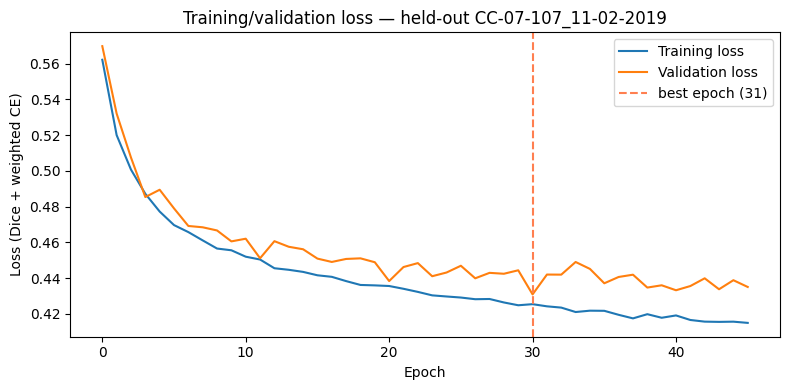

  -> stopped early (best val_loss=0.43093 at epoch 31, 46 epoch(s) run)
  -> F1 score for held-out individual CC-07-107_11-02-2019: 0.7612

===== Fold 2/13 | held-out individual: CC-07-108_11-02-2019 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-48_06-10-2018'), np.str_('CC-07-48_26-05-2018'), np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-48_08-04-2019')] -> ['CC-07-48_06-10-2018', 'CC-07-48_26-05-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_08-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_10-10-2018', 'CC-07-59_20-05-2018', 'CC-07-48_22-05-2018', 'CC-07-48_18-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3']
  val individuals  : [np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-48_04-10-2018')] -> ['CC-07-47_14-02-2018

  -> training took 428.7 s (7.14 min) over 50 epoch(s)


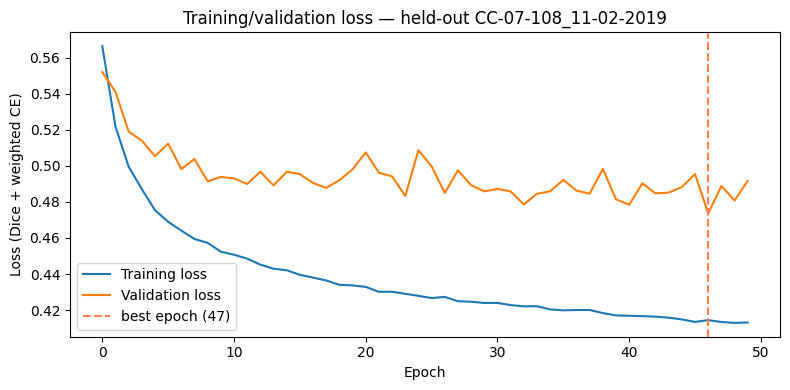

  -> stopped at epoch limit (best val_loss=0.47365 at epoch 47, 50 epoch(s) run)
  -> F1 score for held-out individual CC-07-108_11-02-2019: 0.5927

===== Fold 3/13 | held-out individual: CC-07-115_13-05-2019+14-05-2019 (2 recording(s)) =====
  train individuals: [np.str_('CC-07-48_06-10-2018'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-48_26-05-2018'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-48_18-02-2019')] -> ['CC-07-48_06-10-2018', 'CC-07-48_10-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_26-05-2018', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-47_14-02-2018', 'CC-07-48_08-10-2018', 'CC-07-59_20-05-2018', 'CC-07-48_18-02-2019']
  val individuals  : [np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-48_08-04-2019')] -> ['CC-07-48_22-05-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-0

  -> training took 433.9 s (7.23 min) over 50 epoch(s)


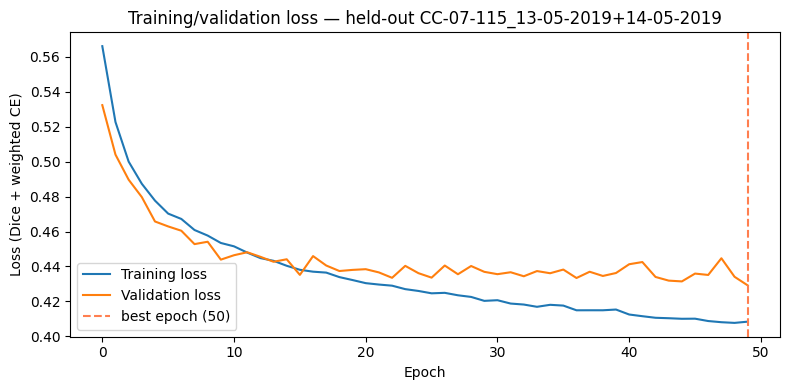

  -> stopped at epoch limit (best val_loss=0.42917 at epoch 50, 50 epoch(s) run)
  -> F1 score for held-out individual CC-07-115_13-05-2019+14-05-2019: 0.6357

===== Fold 4/13 | held-out individual: CC-07-47_14-02-2018 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-48_26-05-2018')] -> ['CC-07-108_11-02-2019', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-59_20-05-2018', 'CC-07-48_08-10-2018', 'CC-07-48_10-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-48_22-05-2018', 'CC-07-48_18-02-2019', 'CC-07-48_26-05-2018']
  val individuals  : [np.str_('CC-07-48_08-04-2019'), np.str_('CC-07-48_06-10-2018')] -> ['CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', '

  -> training took 413.0 s (6.88 min) over 46 epoch(s)


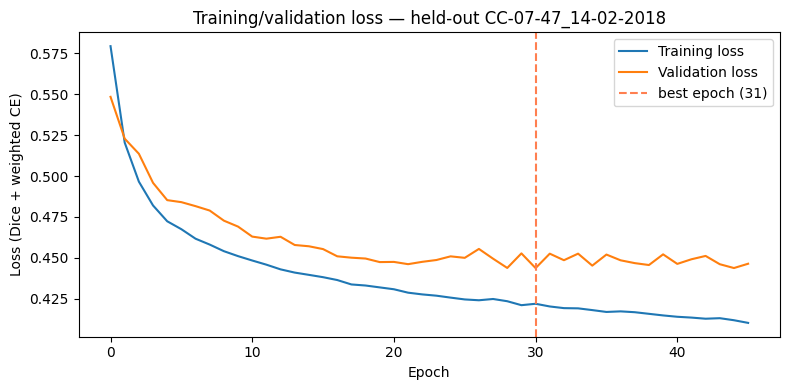

  -> stopped early (best val_loss=0.44376 at epoch 31, 46 epoch(s) run)
  -> F1 score for held-out individual CC-07-47_14-02-2018: 0.8188

===== Fold 5/13 | held-out individual: CC-07-48_04-10-2018 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-48_08-04-2019'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-48_26-05-2018')] -> ['CC-07-48_08-10-2018', 'CC-07-48_22-05-2018', 'CC-07-48_18-02-2019', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-59_20-05-2018', 'CC-07-107_11-02-2019', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_10-10-2018', 'CC-07-48_26-05-2018']
  val individuals  : [np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-48_06-10-2018')] -> ['CC-07-47_14-02-2018

  -> training took 469.4 s (7.82 min) over 50 epoch(s)


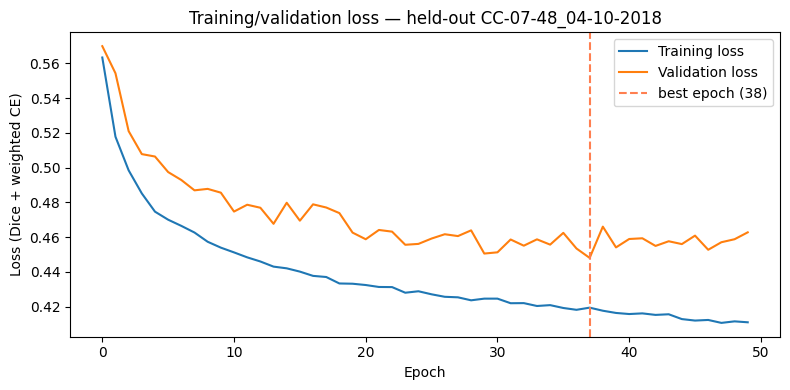

  -> stopped at epoch limit (best val_loss=0.44806 at epoch 38, 50 epoch(s) run)
  -> F1 score for held-out individual CC-07-48_04-10-2018: 0.6567

===== Fold 6/13 | held-out individual: CC-07-48_06-10-2018 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-48_26-05-2018'), np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-47_14-02-2018')] -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_22-05-2018', 'CC-07-59_20-05-2018', 'CC-07-48_04-10-2018', 'CC-07-48_18-02-2019', 'CC-07-108_11-02-2019', 'CC-07-107_11-02-2019', 'CC-07-48_26-05-2018', 'CC-07-48_08-10-2018', 'CC-07-47_14-02-2018']
  val individuals  : [np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-48_08-04-2019')] -> ['CC-07-48_10-10-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04

  -> training took 373.6 s (6.23 min) over 41 epoch(s)


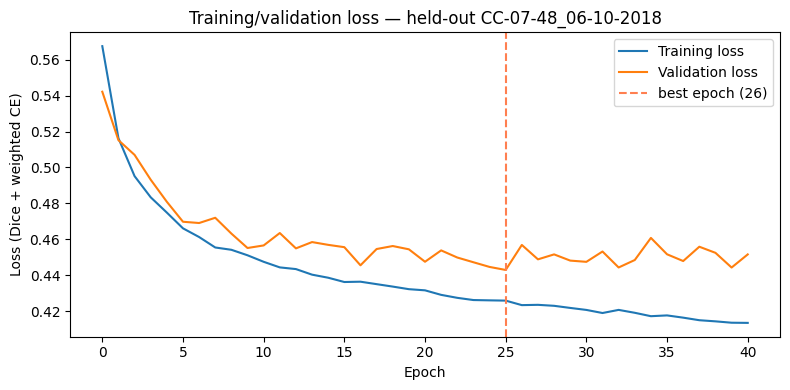

  -> stopped early (best val_loss=0.44300 at epoch 26, 41 epoch(s) run)
  -> F1 score for held-out individual CC-07-48_06-10-2018: 0.6904

===== Fold 7/13 | held-out individual: CC-07-48_08-04-2019 (3 recording(s)) =====
  train individuals: [np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-48_06-10-2018'), np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-48_26-05-2018')] -> ['CC-07-108_11-02-2019', 'CC-07-48_08-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_10-10-2018', 'CC-07-48_06-10-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_04-10-2018', 'CC-07-47_14-02-2018', 'CC-07-48_22-05-2018', 'CC-07-48_26-05-2018']
  val individuals  : [np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-59_20-05-2018')] -> ['CC-07-48_18-02-2019', 'CC-07-59_20-05-2018']
  training class balance (

  -> training took 487.0 s (8.12 min) over 50 epoch(s)


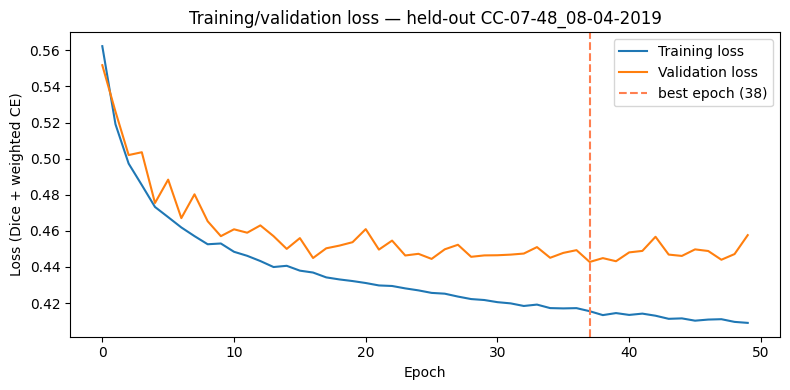

  -> stopped at epoch limit (best val_loss=0.44277 at epoch 38, 50 epoch(s) run)
  -> F1 score for held-out individual CC-07-48_08-04-2019: 0.6795

===== Fold 8/13 | held-out individual: CC-07-48_08-10-2018 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-48_06-10-2018'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-48_08-04-2019'), np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-48_04-10-2018')] -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_06-10-2018', 'CC-07-107_11-02-2019', 'CC-07-108_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_18-02-2019', 'CC-07-47_14-02-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_22-05-2018', 'CC-07-48_04-10-2018']
  val individuals  : [np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-48_26-05-2018')] -> ['CC-07-48_1

  -> training took 396.7 s (6.61 min) over 50 epoch(s)


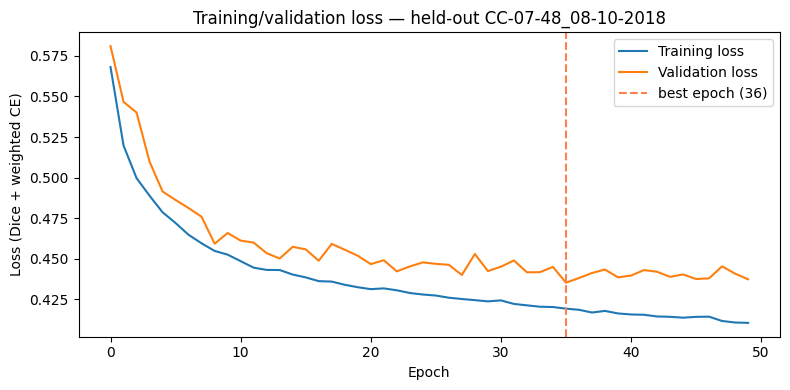

  -> stopped at epoch limit (best val_loss=0.43531 at epoch 36, 50 epoch(s) run)
  -> F1 score for held-out individual CC-07-48_08-10-2018: 0.7182

===== Fold 9/13 | held-out individual: CC-07-48_10-10-2018 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-48_26-05-2018'), np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-48_08-04-2019'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-48_06-10-2018'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-47_14-02-2018')] -> ['CC-07-48_26-05-2018', 'CC-07-48_18-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-59_20-05-2018', 'CC-07-107_11-02-2019', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_06-10-2018', 'CC-07-108_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-47_14-02-2018']
  val individuals  : [np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-48_22-05-2018')] -> ['CC-07-48_0

  -> training took 441.6 s (7.36 min) over 50 epoch(s)


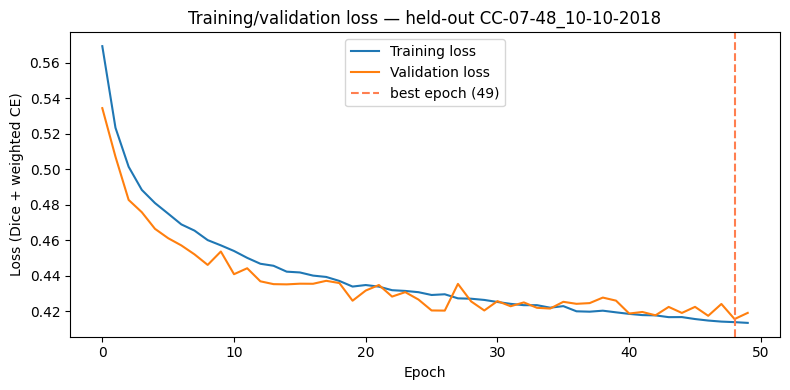

  -> stopped at epoch limit (best val_loss=0.41550 at epoch 49, 50 epoch(s) run)
  -> F1 score for held-out individual CC-07-48_10-10-2018: 0.7942

===== Fold 10/13 | held-out individual: CC-07-48_18-02-2019 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-48_26-05-2018'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-48_08-04-2019'), np.str_('CC-07-48_06-10-2018')] -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-107_11-02-2019', 'CC-07-47_14-02-2018', 'CC-07-48_04-10-2018', 'CC-07-108_11-02-2019', 'CC-07-59_20-05-2018', 'CC-07-48_26-05-2018', 'CC-07-48_10-10-2018', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_06-10-2018']
  val individuals  : [np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-48_22-05-2018')] -> ['CC-07-48_

  -> training took 347.1 s (5.79 min) over 40 epoch(s)


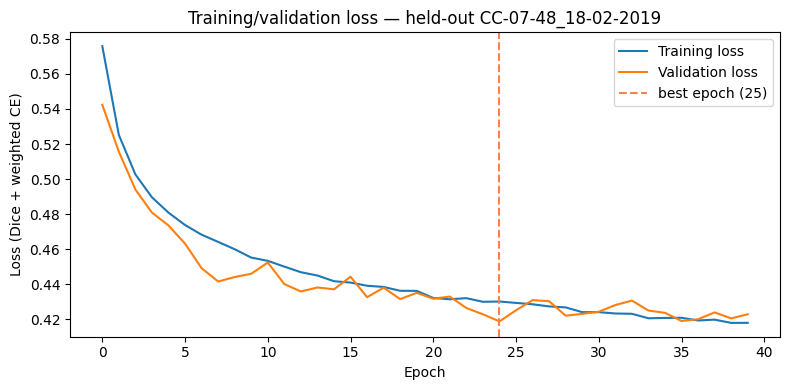

  -> stopped early (best val_loss=0.41879 at epoch 25, 40 epoch(s) run)
  -> F1 score for held-out individual CC-07-48_18-02-2019: 0.6559

===== Fold 11/13 | held-out individual: CC-07-48_22-05-2018 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-48_06-10-2018'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-48_26-05-2018'), np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-48_18-02-2019')] -> ['CC-07-48_08-10-2018', 'CC-07-48_06-10-2018', 'CC-07-59_20-05-2018', 'CC-07-48_10-10-2018', 'CC-07-48_26-05-2018', 'CC-07-47_14-02-2018', 'CC-07-108_11-02-2019', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-48_18-02-2019']
  val individuals  : [np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-48_08-04-2019')] -> ['CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2'

  -> training took 414.2 s (6.90 min) over 50 epoch(s)


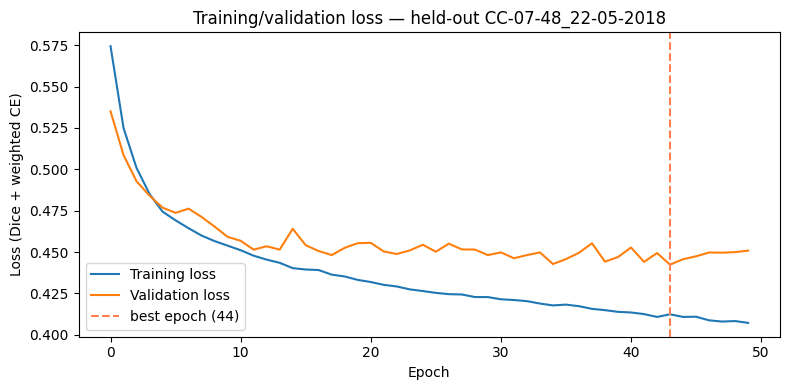

  -> stopped at epoch limit (best val_loss=0.44242 at epoch 44, 50 epoch(s) run)
  -> F1 score for held-out individual CC-07-48_22-05-2018: 0.6777

===== Fold 12/13 | held-out individual: CC-07-48_26-05-2018 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-59_20-05-2018'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-48_06-10-2018'), np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-48_18-02-2019')] -> ['CC-07-48_10-10-2018', 'CC-07-48_22-05-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-59_20-05-2018', 'CC-07-48_04-10-2018', 'CC-07-48_06-10-2018', 'CC-07-48_08-10-2018', 'CC-07-108_11-02-2019', 'CC-07-107_11-02-2019', 'CC-07-48_18-02-2019']
  val individuals  : [np.str_('CC-07-48_08-04-2019'), np.str_('CC-07-47_14-02-2018')] -> ['CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08

  -> training took 404.1 s (6.74 min) over 48 epoch(s)


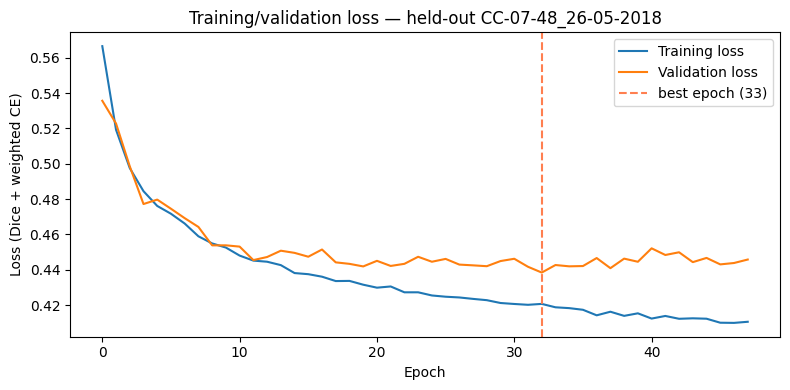

  -> stopped early (best val_loss=0.43847 at epoch 33, 48 epoch(s) run)
  -> F1 score for held-out individual CC-07-48_26-05-2018: 0.7901

===== Fold 13/13 | held-out individual: CC-07-59_20-05-2018 (1 recording(s)) =====
  train individuals: [np.str_('CC-07-48_18-02-2019'), np.str_('CC-07-48_10-10-2018'), np.str_('CC-07-107_11-02-2019'), np.str_('CC-07-48_04-10-2018'), np.str_('CC-07-48_08-10-2018'), np.str_('CC-07-47_14-02-2018'), np.str_('CC-07-115_13-05-2019+14-05-2019'), np.str_('CC-07-108_11-02-2019'), np.str_('CC-07-48_08-04-2019'), np.str_('CC-07-48_26-05-2018')] -> ['CC-07-48_18-02-2019', 'CC-07-48_10-10-2018', 'CC-07-107_11-02-2019', 'CC-07-48_04-10-2018', 'CC-07-48_08-10-2018', 'CC-07-47_14-02-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019', 'CC-07-108_11-02-2019', 'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_26-05-2018']
  val individuals  : [np.str_('CC-07-48_22-05-2018'), np.str_('CC-07-48_06-10-2018')] -> ['CC-07-48_22-05-201

  -> training took 419.1 s (6.99 min) over 50 epoch(s)


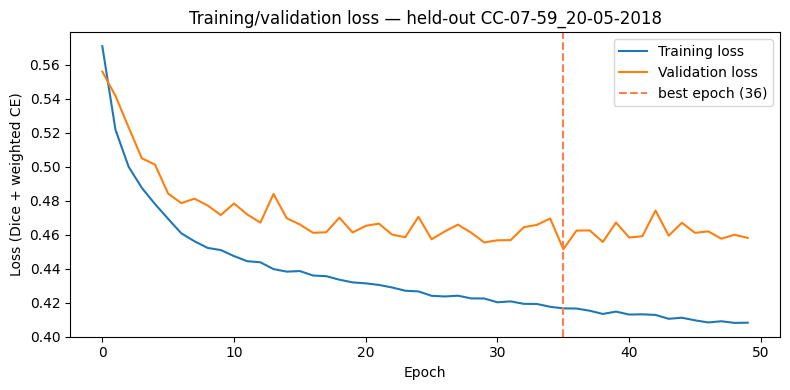

  -> stopped at epoch limit (best val_loss=0.45144 at epoch 36, 50 epoch(s) run)
  -> F1 score for held-out individual CC-07-59_20-05-2018: 0.7935


,fold,test_individual,n_test_recordings,n_train_individuals,n_val_individuals,n_epochs_run,stopped_early,best_epoch,best_val_loss,training_duration_s,macro_F1,train_n_Other,train_n_Breathing,train_n_Feeding,train_n_Gliding,train_n_Resting,train_n_Scratching,train_n_Swimming
0,1,CC-07-107_11-02-2019,1,10,2,46,True,31,0.430929,422.566305,0.761217,59021,307818,77194,105076,1769073,74253,1259534
1,2,CC-07-108_11-02-2019,1,10,2,50,False,47,0.473651,428.691680,0.592657,67461,359522,112932,161432,2343190,87922,1275033
2,3,CC-07-115_13-05-2019+14-05-2019,2,10,2,50,False,50,0.429166,433.938117,0.635658,54740,285114,118183,100256,1516709,68747,1082066
3,4,CC-07-47_14-02-2018,1,10,2,46,True,31,0.443764,413.037378,0.818813,47755,331293,85957,147332,1994440,66542,1314387
4,5,CC-07-48_04-10-2018,1,10,2,50,False,38,0.448057,469.387973,0.656746,55698,323888,87117,158343,2129198,70286,1268071
5,6,CC-07-48_06-10-2018,1,10,2,41,True,26,0.443003,373.603498,0.690419,46848,320423,85957,145301,1980223,66542,1378535
6,7,CC-07-48_08-04-2019,3,10,2,50,False,38,0.442775,486.964924,0.679480,53606,328243,94866,122905,1666208,70820,1248529
7,8,CC-07-48_08-10-2018,1,10,2,50,False,36,0.435307,396.732919,0.718173,64539,310682,117000,135689,2006975,53435,1397106
8,9,CC-07-48_10-10-2018,1,10,2,50,False,49,0.415504,441.628528,0.794223,66903,313346,124557,138777,1946407,74292,1402284
9,10,CC-07-48_18-02-2019,1,10,2,40,True,25,0.418794,347.104508,0.655878,63123,292596,124429,128633,1609037,70760,1288008


In [17]:
fold_results = []
per_class_f1_by_fold = {}
summary_path = os.path.join(DIR_OUT_BASE, "loocv_f1_summary.csv")

for fold_idx, test_individual in enumerate(INDIVIDUAL_IDS):

    test_names = INDIVIDUAL_TO_NAMES[test_individual]
    remaining_individuals = [i for i in INDIVIDUAL_IDS if i != test_individual]

    rng = np.random.RandomState(fold_idx)   # reproducible train/val split per fold
    remaining_shuffled = list(rng.permutation(remaining_individuals))
    val_individuals = remaining_shuffled[:N_VAL_INDIVIDUALS_PER_FOLD]
    train_individuals = remaining_shuffled[N_VAL_INDIVIDUALS_PER_FOLD:]

    NAMES_VAL_fold = [n for i in val_individuals for n in INDIVIDUAL_TO_NAMES[i]]
    NAMES_TRAIN_fold = [n for i in train_individuals for n in INDIVIDUAL_TO_NAMES[i]]

    print(f"\n===== Fold {fold_idx+1}/{len(INDIVIDUAL_IDS)} | held-out individual: {test_individual} "
          f"({len(test_names)} recording(s)) =====")
    print("  train individuals:", train_individuals, "->", NAMES_TRAIN_fold)
    print("  val individuals  :", val_individuals, "->", NAMES_VAL_fold)

    train_balance = class_balance(NAMES_TRAIN_fold)
    print("  training class balance (timesteps):")
    print(train_balance.to_string())
    missing_classes = train_balance[train_balance == 0].index.tolist()
    if missing_classes:
        print(f"  WARNING: {missing_classes} have ZERO training examples in this fold "
              f"-> the model cannot learn them and will never predict them for {test_individual}.")

    DIR_OUT_fold = os.path.join(DIR_OUT_BASE, "fold_" + test_individual)
    os.makedirs(DIR_OUT_fold, exist_ok=True)

    model = VNet4Levels(len(DESCRIPTORS_SELEC), len(CLASSES), MODEL_DEPTH, dropout_rate=DROPOUT).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR_initial)
    trainer = Trainer(model, optimizer, dice_ce_loss, BATCH_SIZE, ponde, device,
                       save_path=os.path.join(DIR_OUT_fold, "model.pth"))

    train_gen = oneEpoch_generator_window(NAMES_TRAIN_fold, size=NB_TRAIN_PER_EPOCH)
    val_gen = oneEpoch_generator_window(NAMES_VAL_fold, size=NB_VAL_PER_EPOCH)

    trainer.train(train_gen, val_gen, epochs=EPOCHS_PER_FOLD, patience=PATIENCE)

    print(f"  -> training took {trainer.total_duration:.1f} s "
          f"({trainer.total_duration/60:.2f} min) over {len(trainer.val_losses)} epoch(s)")

    plot_loss_curve(trainer, f"Training/validation loss — held-out {test_individual}",
                     save_path=os.path.join(DIR_OUT_fold, "loss_curve.png"))

    # reload the best checkpoint of this fold before testing on the held-out individual
    model.load_state_dict(torch.load(trainer.save_path, weights_only=True))
    macro_f1, per_class_f1 = evaluate_names(model, device, test_names)

    print(f"  -> stopped {'early' if trainer.stopped_early else 'at epoch limit'} "
          f"(best val_loss={trainer.best_loss:.5f} at epoch {trainer.best_epoch+1}, "
          f"{len(trainer.val_losses)} epoch(s) run)")

    fold_results.append({
        "fold": fold_idx + 1,
        "test_individual": test_individual,
        "n_test_recordings": len(test_names),
        "n_train_individuals": len(train_individuals),
        "n_val_individuals": len(val_individuals),
        "n_epochs_run": len(trainer.val_losses),
        "stopped_early": trainer.stopped_early,
        "best_epoch": trainer.best_epoch + 1,
        "best_val_loss": trainer.best_loss,
        "training_duration_s": trainer.total_duration,
        "macro_F1": macro_f1,
        **{f"train_n_{c}": int(train_balance[c]) for c in CLASS_NAMES},
    })
    per_class_f1_by_fold[test_individual] = per_class_f1["F1_score"]

    print(f"  -> F1 score for held-out individual {test_individual}: {macro_f1:.4f}")

    # persist progress after every fold, in case of interruption
    pd.DataFrame(fold_results).to_csv(summary_path, index=False)

    del model, optimizer, trainer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(fold_results)
results_df

## Results

In [18]:
mean_f1 = results_df["macro_F1"].mean()
std_f1 = results_df["macro_F1"].std()

print(f"LOOCV macro F1-score: {mean_f1:.4f} +/- {std_f1:.4f}  (n={len(results_df)} folds)")
results_df

LOOCV macro F1-score: 0.7127 +/- 0.0721  (n=13 folds)


,fold,test_individual,n_test_recordings,n_train_individuals,n_val_individuals,n_epochs_run,stopped_early,best_epoch,best_val_loss,training_duration_s,macro_F1,train_n_Other,train_n_Breathing,train_n_Feeding,train_n_Gliding,train_n_Resting,train_n_Scratching,train_n_Swimming
0,1,CC-07-107_11-02-2019,1,10,2,46,True,31,0.430929,422.566305,0.761217,59021,307818,77194,105076,1769073,74253,1259534
1,2,CC-07-108_11-02-2019,1,10,2,50,False,47,0.473651,428.691680,0.592657,67461,359522,112932,161432,2343190,87922,1275033
2,3,CC-07-115_13-05-2019+14-05-2019,2,10,2,50,False,50,0.429166,433.938117,0.635658,54740,285114,118183,100256,1516709,68747,1082066
3,4,CC-07-47_14-02-2018,1,10,2,46,True,31,0.443764,413.037378,0.818813,47755,331293,85957,147332,1994440,66542,1314387
4,5,CC-07-48_04-10-2018,1,10,2,50,False,38,0.448057,469.387973,0.656746,55698,323888,87117,158343,2129198,70286,1268071
5,6,CC-07-48_06-10-2018,1,10,2,41,True,26,0.443003,373.603498,0.690419,46848,320423,85957,145301,1980223,66542,1378535
6,7,CC-07-48_08-04-2019,3,10,2,50,False,38,0.442775,486.964924,0.679480,53606,328243,94866,122905,1666208,70820,1248529
7,8,CC-07-48_08-10-2018,1,10,2,50,False,36,0.435307,396.732919,0.718173,64539,310682,117000,135689,2006975,53435,1397106
8,9,CC-07-48_10-10-2018,1,10,2,50,False,49,0.415504,441.628528,0.794223,66903,313346,124557,138777,1946407,74292,1402284
9,10,CC-07-48_18-02-2019,1,10,2,40,True,25,0.418794,347.104508,0.655878,63123,292596,124429,128633,1609037,70760,1288008


In [19]:
per_class_f1_df = pd.DataFrame(per_class_f1_by_fold)  # rows = class, columns = held-out turtle
per_class_f1_df["mean_F1"] = per_class_f1_df.mean(axis=1)
per_class_f1_df["std_F1"] = per_class_f1_df.drop(columns="mean_F1").std(axis=1)
per_class_f1_df.to_csv(os.path.join(DIR_OUT_BASE, "loocv_per_class_f1.csv"))
per_class_f1_df

,CC-07-107_11-02-2019,CC-07-108_11-02-2019,CC-07-115_13-05-2019+14-05-2019,CC-07-47_14-02-2018,CC-07-48_04-10-2018,CC-07-48_06-10-2018,CC-07-48_08-04-2019,CC-07-48_08-10-2018,CC-07-48_10-10-2018,CC-07-48_18-02-2019,CC-07-48_22-05-2018,CC-07-48_26-05-2018,CC-07-59_20-05-2018,mean_F1,std_F1
Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001687,NaN,NaN,0.001687,NaN
Breathing,0.917237,0.583657,0.943259,0.649165,0.964866,0.740349,0.956759,0.940157,0.756349,0.947232,0.946715,0.919609,0.854712,0.855390,0.129519
Feeding,0.796301,0.702468,0.462430,NaN,0.263689,0.690653,0.301635,0.483782,NaN,0.030441,0.518416,0.560568,0.861503,0.515626,0.247890
Gliding,0.787733,0.496558,0.509159,NaN,0.277199,0.533823,0.733977,0.803799,0.523394,0.635944,0.741426,0.695102,0.783917,0.626836,0.160581
Resting,0.957952,0.871925,0.922573,NaN,0.935462,0.954520,0.944354,0.985305,0.960185,0.978887,0.978420,0.951628,0.977784,0.951583,0.031496
Scratching,0.183615,0.030804,0.130289,NaN,NaN,0.411580,0.273211,0.231909,NaN,0.429244,0.648079,0.761616,0.387667,0.348801,0.227899
Swimming,0.924463,0.870531,0.846238,0.988461,0.842512,0.811589,0.866946,0.864086,0.936964,0.913522,0.909392,0.851861,0.895507,0.886313,0.047632


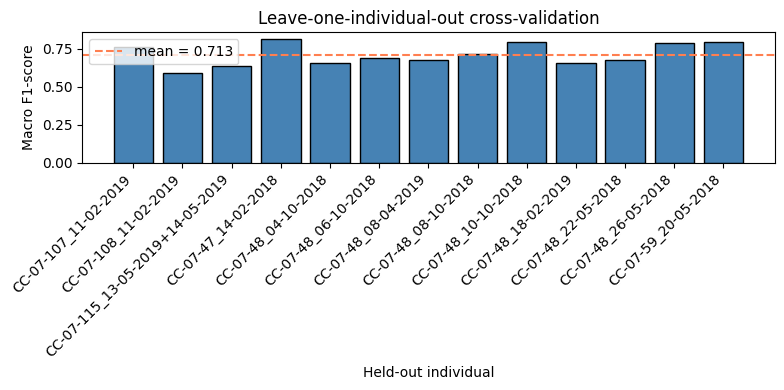

In [20]:
plt.figure(figsize=(8, 4))
plt.bar(results_df["test_individual"], results_df["macro_F1"], color="steelblue", edgecolor="k")
plt.axhline(mean_f1, color="coral", linestyle="--", label=f"mean = {mean_f1:.3f}")
plt.ylabel("Macro F1-score")
plt.xlabel("Held-out individual")
plt.title("Leave-one-individual-out cross-validation")
plt.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUT_BASE, "loocv_f1_per_fold.png"))
plt.show()